<a href="https://colab.research.google.com/github/Odysseussss/-Portal-de-Estudos-Fabric/blob/main/IfoodCase_Resolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# iFood Case: otimização de campanha
Nesta análise, procuro entender quais clientes têm maior propensão a responder à campanha e como transformar essa propensão em uma decisão financeira. Durante a exploração inicial, identifiquei alguns valores potencialmente inconsistentes, especialmente em ano de nascimento e renda. Também observei que a base não apresenta um grupo de controle ou uma identificação de clientes não expostos à campanha. Por isso, trato o modelo como uma estimativa de propensão histórica, e não como uma medida de efeito causal.

## 1. Preparação

Vou carregar os dados diretamente do GitHub para manter o notebook reproduzível.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', palette='colorblind')
URL = 'https://raw.githubusercontent.com/Odysseussss/IfoodCase/main/ifood_case_data.csv'

try:
    df = pd.read_csv(URL)
    print('Dados carregados do GitHub.')
except Exception as error:
    print(f'Não foi possível carregar os dados: {error}')
else:
    print(f'{df.shape[0]:,} clientes e {df.shape[1]} variáveis.')
    display(df.head(3))

Dados carregados do GitHub.
2,240 clientes e 29 variáveis.


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0


## 2. Qualidade dos dados e outliers

Antes de modelar, vou verificar duplicidades, ausências e valores extremos.

In [ ]:
TARGET = 'Response'
CAMPAIGNS = [f'AcceptedCmp{i}' for i in range(1, 6)]
SPEND = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
PURCHASES = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']

print(f'Duplicidades completas: {df.duplicated().sum()}')
print(f'IDs duplicados: {df["ID"].duplicated().sum()}')
missing = pd.DataFrame({'ausentes':df.isna().sum(), 'percentual':df.isna().mean().mul(100)}).query('ausentes > 0')
display(missing)

# Utilização do IQR para localizar valores extremos
outlier_rows = []
for column in ['Year_Birth', 'Income', 'Recency'] + SPEND + PURCHASES:
    values = df[column].dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append([column, low, high, ((values < low) | (values > high)).sum()])
outliers = pd.DataFrame(outlier_rows, columns=['variavel', 'limite_inferior', 'limite_superior', 'qtd_outliers'])
display(outliers.sort_values('qtd_outliers', ascending=False).head(10))

Duplicidades completas: 0
IDs duplicados: 0


,ausentes,percentual
Income,24,1.071429


,variavel,limite_inferior,limite_superior,qtd_outliers
7,MntSweetProducts,-47.0,81.0,248
4,MntFruits,-47.0,81.0,227
6,MntFishProducts,-67.5,120.5,223
8,MntGoldProds,-61.5,126.5,207
5,MntMeatProducts,-308.0,556.0,175
3,MntWines,-697.0,1225.0,35
10,NumCatalogPurchases,-6.0,10.0,23
1,Income,-14525.5,118350.5,8
9,NumWebPurchases,-4.0,12.0,4
0,Year_Birth,1932.0,2004.0,3


### Decisão de tratamento

Aqui eu mantive os outliers estatísticos, porque não há evidência suficiente para dizer que sejam erros. Sinalizei inelegíveis apenas dois casos claramente suspeitos:

- clientes nascidos antes de 1936, optando como regra de negócio que o público analisado são pessoas fisicas com menos 90 anos;
- renda igual a 666.666, que parece ser erro de cadastro.

A base original será preservada. O modelo principal usará `df_valid`, enquanto `df_flagged` ficará disponível para auditoria e eventual correção cadastral.

In [ ]:
df_quality = df.copy()

df_quality['invalid_birth_year'] = df_quality['Year_Birth'] < 1936
df_quality['invalid_income'] = df_quality['Income'] == 666666
df_quality['eligible_for_analysis'] = ~(df_quality['invalid_birth_year'] | df_quality['invalid_income'])

df_quality['validation_reason'] = np.select(
    [
        df_quality['invalid_birth_year'] & df_quality['invalid_income'],
        df_quality['invalid_birth_year'],
        df_quality['invalid_income']
    ],
    [
        'Ano de nascimento e renda suspeitos',
        'Ano de nascimento suspeito',
        'Renda suspeita'
    ],
    default='Aprovado para análise'
)

df_valid = df_quality[df_quality['eligible_for_analysis']].copy()
df_flagged = df_quality[~df_quality['eligible_for_analysis']].copy()

print(f"Clientes aprovados: {len(df_valid):,}")
print(f"Clientes sinalizados: {len(df_flagged):,} flagged: {len(df_flagged) / len(df_quality):.2%}")

if (len(df_flagged) / len(df_quality)) < 0.01:
    print("pode seguir")
else:
    print("outliers acima de 1% da base")

display(df_flagged[["ID", "Year_Birth", "Income", "validation_reason"]])


Clientes aprovados: 2,236
Clientes sinalizados: 4 flagged: 0.18%
pode seguir


,ID,Year_Birth,Income,validation_reason
192,7829,1900,36640.0,Ano de nascimento suspeito
239,11004,1893,60182.0,Ano de nascimento suspeito
339,1150,1899,83532.0,Ano de nascimento suspeito
2233,9432,1977,666666.0,Renda suspeita


## 3. Variáveis e diagnóstico financeiro

Criação das variáveis simples de valor, frequência e histórico de engajamento. O custo de contato é 3 MU e a receita por conversão é 11 MU.

In [ ]:
def create_features(data):
    data = data.copy()
    data.loc[data['Year_Birth'] < 1900, 'Year_Birth'] = np.nan
    data.loc[data['Income'] == 666666, 'Income'] = np.nan
    data['TotalSpend'] = data[SPEND].sum(axis=1)
    data['TotalPurchases'] = data[PURCHASES].sum(axis=1)
    data['PreviousAcceptedCampaigns'] = data[CAMPAIGNS].sum(axis=1)
    data['HouseholdDependents'] = data['Kidhome'] + data['Teenhome']
    return data

model_df = create_features(df_valid)
all_model_df = create_features(df_quality)

COST = float(df['Z_CostContact'].mode().iloc[0])
REVENUE = float(df['Z_Revenue'].mode().iloc[0])
BREAK_EVEN = COST / REVENUE
pilot_result = df[TARGET].sum() * REVENUE - len(df) * COST

print(f'Taxa de conversão piloto: {df[TARGET].mean():.2%}')
print(f'Resultado da campanha piloto: {pilot_result:,.0f} MU')
print(f'Break-even: {BREAK_EVEN:.2%}')

Taxa de conversão piloto: 14.91%
Resultado da campanha piloto: -3,046 MU
Break-even: 27.27%


## 4. Leitura dos segmentos

Antes do modelo, vou observar se o histórico de campanhas anteriores já separa grupos com comportamentos diferentes.

,clientes,conversoes,taxa_resposta,lucro_esperado_por_cliente
PreviousAcceptedCampaigns,,,,
0,1.774,146,"8,23%","-2,09"
1,324,101,"31,17%","0,43"
2,83,42,"50,60%","2,57"
3,44,35,"79,55%","5,75"
4,11,10,"90,91%","7,00"


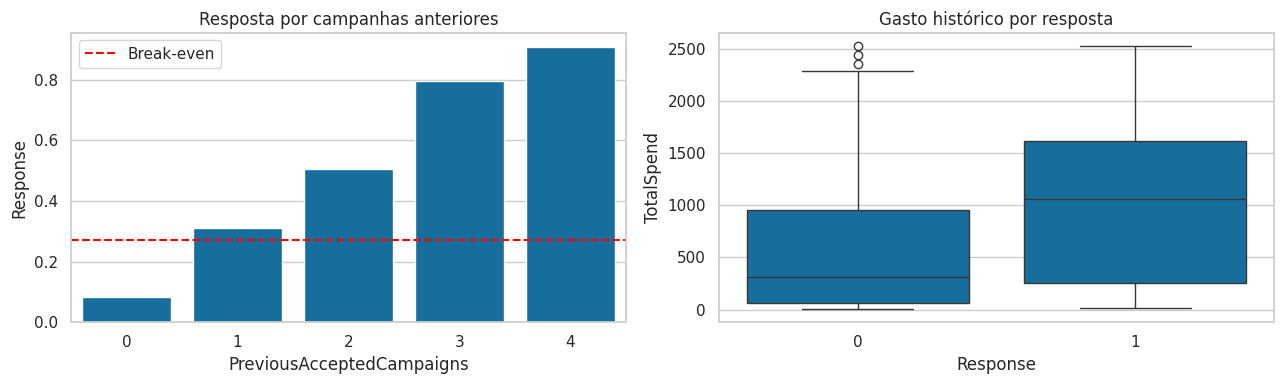

In [ ]:
segments = (
    model_df.groupby('PreviousAcceptedCampaigns')[TARGET]
    .agg(clientes='size', conversoes='sum', taxa_resposta='mean')
    .assign(lucro_esperado_por_cliente=lambda x: x['taxa_resposta'] * REVENUE - COST)
)

display(segments.style.format({
    'taxa_resposta': '{:.2%}',
    'lucro_esperado_por_cliente': '{:.2f}'
}, decimal=',', thousands='.'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=model_df, x='PreviousAcceptedCampaigns', y=TARGET, estimator='mean', errorbar=None, ax=axes[0])
axes[0].axhline(BREAK_EVEN, color='red', linestyle='--', label='Break-even')
axes[0].set_title('Resposta por campanhas anteriores')
axes[0].legend()
sns.boxplot(data=model_df, x=TARGET, y='TotalSpend', ax=axes[1])
axes[1].set_title('Gasto histórico por resposta')
plt.tight_layout()


### Taxa de resposta por recência

Clientes com compra mais recente tendem a estar mais engajados. Este gráfico ajuda a verificar se a recência também aparece como um sinal útil para a campanha.

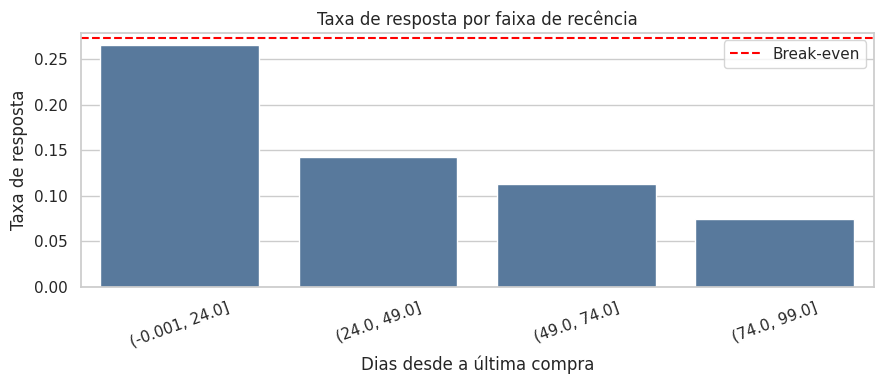

In [ ]:
recency_analysis = model_df.copy()
recency_analysis['faixa_recencia'] = pd.qcut(recency_analysis['Recency'], q=4, duplicates='drop')
recency_summary = recency_analysis.groupby('faixa_recencia', observed=False)[TARGET].mean().reset_index(name='taxa_resposta')

plt.figure(figsize=(9, 4))
sns.barplot(data=recency_summary, x='faixa_recencia', y='taxa_resposta', color='#4C78A8')
plt.axhline(BREAK_EVEN, color='red', linestyle='--', label='Break-even')
plt.title('Taxa de resposta por faixa de recência')
plt.xlabel('Dias desde a última compra')
plt.ylabel('Taxa de resposta')
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()

## 5. Modelo de propensão

Optei por regressão logística porque ela gera probabilidades. O pipeline concentra a imputação, a codificação e a padronização no conjunto de treino.

In [ ]:
drop_columns = ['ID', TARGET, 'Z_CostContact', 'Z_Revenue', 'Dt_Customer', 'invalid_birth_year', 'invalid_income', 'eligible_for_analysis', 'validation_reason']
X = model_df.drop(columns=drop_columns)
y = model_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)

numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer(transformers=[
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_columns),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_columns)
])
model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=2000, random_state=42))])
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_test)[:, 1]
print(f'ROC-AUC: {roc_auc_score(y_test, probabilities):.3f}')
print(f'PR-AUC: {average_precision_score(y_test, probabilities):.3f}')

ROC-AUC: 0.893
PR-AUC: 0.618


### O que o modelo descobriu

O modelo apresentou ROC-AUC de 0,893 e PR-AUC de 0,618. Em termos práticos, isso indica que a regressão logística consegue ordenar razoavelmente bem os clientes entre maior e menor propensão de resposta, mesmo com a resposta positiva representando apenas cerca de 15% da base.

Esses resultados justificam o uso da regressão logística como baseline para priorização. Eles não comprovam causalidade nem garantem que cada cliente classificado como prioritário irá comprar; a confirmação deve acontecer em uma nova campanha com grupo de controle.

## 6. Decisão financeira e análise de sensibilidade

O modelo principal será avaliado somente nos clientes elegíveis. Como controle de sensibilidade, também aplico a verificação do que aconteceria se os registros sinalizados fossem reintegrados após uma eventual correção cadastral para termos os 2 cenarios.

In [ ]:
def evaluate_strategy(data, selection):
    selected = data[selection].astype(bool)
    contacts = selected.sum()
    conversions = data.loc[selected, TARGET].sum()
    revenue = conversions * REVENUE
    cost = contacts * COST
    return pd.Series({'clientes_contactados':contacts, 'conversoes':conversions, 'taxa_conversao':conversions / contacts if contacts else 0, 'custo':cost, 'receita':revenue, 'resultado':revenue - cost})

# Aplicação do modelo ao teste para medir desempenho fora da amostra.
test_results = X_test.copy()
test_results[TARGET] = y_test.values
test_results['probability'] = probabilities
test_results['model_selected'] = test_results['probability'] >= BREAK_EVEN
test_results['baseline_selected'] = test_results['PreviousAcceptedCampaigns'] >= 1

comparison_test = pd.DataFrame({
    'todos': evaluate_strategy(test_results.assign(all_selected=True), 'all_selected'),
    'baseline': evaluate_strategy(test_results, 'baseline_selected'),
    'regressao_logistica': evaluate_strategy(test_results, 'model_selected')
}).T
display(comparison_test.style.format({
    'clientes_contactados': '{:,.0f}', 'conversoes': '{:,.0f}',
    'taxa_conversao': '{:.2%}',
    'custo': '{:,.2f}', 'receita': '{:,.2f}', 'resultado': '{:,.2f}'
}, decimal=',', thousands='.'))

# Sensibilidade: Utilização do modelo treinado nos elegíveis para pontuar também a base completa.
all_features = all_model_df.drop(columns=drop_columns)
all_probabilities = model.predict_proba(all_features)[:, 1]
all_scored = all_model_df[[TARGET]].copy()
all_scored['model_selected'] = all_probabilities >= BREAK_EVEN
all_scored['eligible_for_analysis'] = all_model_df['eligible_for_analysis']

sensitivity = pd.DataFrame({
    'somente_elegiveis': evaluate_strategy(all_scored[all_scored['eligible_for_analysis']], 'model_selected'),
    'base_completa': evaluate_strategy(all_scored, 'model_selected')
}).T
display(sensitivity.style.format({
    'clientes_contactados': '{:,.0f}', 'conversoes': '{:,.0f}',
    'taxa_conversao': '{:.2%}',
    'custo': '{:,.2f}', 'receita': '{:,.2f}', 'resultado': '{:,.2f}'
}, decimal=',', thousands='.'))

,clientes_contactados,conversoes,taxa_conversao,custo,receita,resultado
todos,559,83,"14,85%","1.677,00","913,00","-764,00"
baseline,121,48,"39,67%","363,00","528,00","165,00"
regressao_logistica,95,53,"55,79%","285,00","583,00","298,00"


,clientes_contactados,conversoes,taxa_conversao,custo,receita,resultado
somente_elegiveis,373,218,"58,45%","1.119,00","2.398,00","1.279,00"
base_completa,374,218,"58,29%","1.122,00","2.398,00","1.276,00"


### O que a comparação financeira mostrou

No conjunto de teste, contactar todos os clientes teria resultado em prejuízo, enquanto o baseline comportamental e a regressão logística apresentaram resultado positivo. O modelo selecionou menos clientes e concentrou o contato em uma faixa com maior conversão esperada.

Os quatro registros sinalizados representam apenas 0,18% da base. A análise de sensibilidade permite verificar que deixá-los fora do treino principal não altera materialmente a recomendação; eles foram separados por qualidade cadastral e permanecem disponíveis para auditoria.

## 7. Score de priorização

Demonstração da probabilidade prevista em uma decisão operacional. O cliente recebe um score, uma estimativa de lucro esperado e uma faixa de prioridade.

A regressão logística foi ajustada para usar a probabilidade prevista diretamente na regra financeira.

In [ ]:
# Treinamento do modelo final com todos os clientes elegíveis.
X_all = model_df.drop(columns=drop_columns)
y_all = model_df[TARGET]
model.fit(X_all, y_all)

score_df = model_df[['ID', 'PreviousAcceptedCampaigns', 'TotalSpend', 'Recency']].copy()
score_df['probabilidade_resposta'] = model.predict_proba(X_all)[:, 1]
score_df['lucro_esperado'] = score_df['probabilidade_resposta'] * REVENUE - COST
score_df['prioridade'] = score_df['lucro_esperado'].rank(ascending=False, method='first').astype(int)

score_df['faixa_prioridade'] = np.select(
    [
        score_df['lucro_esperado'] < 0,
        score_df['probabilidade_resposta'] >= 0.50,
        score_df['probabilidade_resposta'] >= BREAK_EVEN
    ],
    ['Não priorizar', 'Alta prioridade', 'Prioridade de teste'],
    default='Não priorizar'
)

score_summary = (score_df.groupby('faixa_prioridade', sort=False)
    .agg(clientes=('ID', 'size'), probabilidade_media=('probabilidade_resposta', 'mean'), lucro_esperado_total=('lucro_esperado', 'sum'))
    .sort_values('lucro_esperado_total', ascending=False))

# Comparação do lucro esperado com o prejuízo acumulado da campanha piloto.
score_summary['resultado_acumulado'] = pilot_result + score_summary['lucro_esperado_total']
score_summary['%_prejuizo_coberto'] = (
    score_summary['lucro_esperado_total'].clip(lower=0) / abs(pilot_result)
)
display(score_summary.style.format({
    'probabilidade_media': '{:.1%}',
    'lucro_esperado_total': '{:,.1f}',
    'resultado_acumulado': '{:,.1f}',
    '%_prejuizo_coberto': '{:.2%}'
}, decimal=',', thousands='.'))
display(score_df.sort_values('prioridade').head(10))

,clientes,probabilidade_media,lucro_esperado_total,resultado_acumulado,%_prejuizo_coberto
faixa_prioridade,,,,,
Alta prioridade,200,"73,4%","1.014,0","-2.032,0","33,29%"
Prioridade de teste,168,"38,1%","199,9","-2.846,1","6,56%"
Não priorizar,1.868,"6,6%","-4.248,2","-7.294,2","0,00%"


,ID,PreviousAcceptedCampaigns,TotalSpend,Recency,probabilidade_resposta,lucro_esperado,prioridade,faixa_prioridade
430,3725,4,1688,1,0.992011,7.912120,1,Alta prioridade
1961,3009,3,1766,8,0.990350,7.893846,2,Alta prioridade
252,10089,4,1112,5,0.986270,7.848970,3,Alta prioridade
1845,7872,3,557,7,0.979462,7.774082,4,Alta prioridade
586,9058,3,1867,65,0.976559,7.742154,5,Alta prioridade
336,7381,3,1442,10,0.974931,7.724236,6,Alta prioridade
1528,830,2,1658,5,0.972163,7.693797,7,Alta prioridade
1710,477,4,2157,31,0.970801,7.678816,8,Alta prioridade
1722,569,3,1991,32,0.965098,7.616080,9,Alta prioridade
987,4580,3,2486,46,0.963399,7.597387,10,Alta prioridade


### Como interpretar o retorno do score

A faixa de alta prioridade apresenta lucro esperado positivo de aproximadamente 1.014 MU. Porém, a campanha piloto deixou um prejuízo de 3.046 MU. Por isso, o resultado acumulado continua negativo em aproximadamente 2.032 MU:

`-3.046 MU + 1.014 MU = -2.032 MU`

Isso não significa que a alta prioridade dê prejuízo. Significa que ela recupera cerca de 33% da perda anterior, mas não é suficiente para compensar todo o prejuízo em uma única campanha. A nova campanha melhora o resultado, mas ainda começa carregando a perda histórica.

### Distribuição das probabilidades previstas

A linha vermelha representa o break-even de 27,27%. Clientes à direita dessa linha possuem lucro esperado positivo sob as premissas atuais.

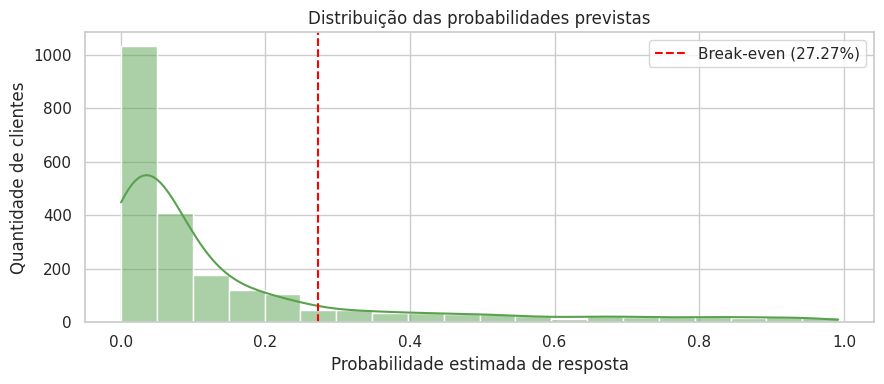

In [ ]:
plt.figure(figsize=(9, 4))
score_distribution = score_df[['probabilidade_resposta']].copy()
sns.histplot(data=score_distribution, x='probabilidade_resposta', bins=20, kde=True, color='#59A14F')
plt.axvline(BREAK_EVEN, color='red', linestyle='--', label=f'Break-even ({BREAK_EVEN:.2%})')
plt.title('Distribuição das probabilidades previstas')
plt.xlabel('Probabilidade estimada de resposta')
plt.ylabel('Quantidade de clientes')
plt.legend()
plt.tight_layout()

In [ ]:
# Simulação de diferentes limites de contato para apoiar a decisão operacional.
capacity_rows = []
for share in [0.10, 0.25, 0.50, 1.00]:
    n_contacts = int(len(score_df) * share)
    selected = score_df.nsmallest(n_contacts, 'prioridade')
    capacity_rows.append({
        'percentual_base': share,
        'clientes_contactados': n_contacts,
        'probabilidade_media': selected['probabilidade_resposta'].mean(),
        'lucro_esperado_total': selected['lucro_esperado'].sum()
    })

capacity_analysis = pd.DataFrame(capacity_rows)
display(capacity_analysis.style.format({
    'percentual_base': '{:.0%}',
    'probabilidade_media': '{:.2%}',
    'lucro_esperado_total': '{:,.2f}'
}, decimal=',', thousands='.'))

,percentual_base,clientes_contactados,probabilidade_media,lucro_esperado_total
0,10%,223,"70,79%","1.067,43"
1,25%,559,"45,05%","1.093,00"
2,50%,1.118,"27,48%","25,78"
3,100%,2.236,"14,94%","-3.034,22"


### Lucro esperado acumulado por prioridade

Este gráfico mostra o lucro esperado acumulado conforme aumentamos o número de contatos. A linha vermelha indica o lucro necessário para recuperar o prejuízo da campanha piloto.

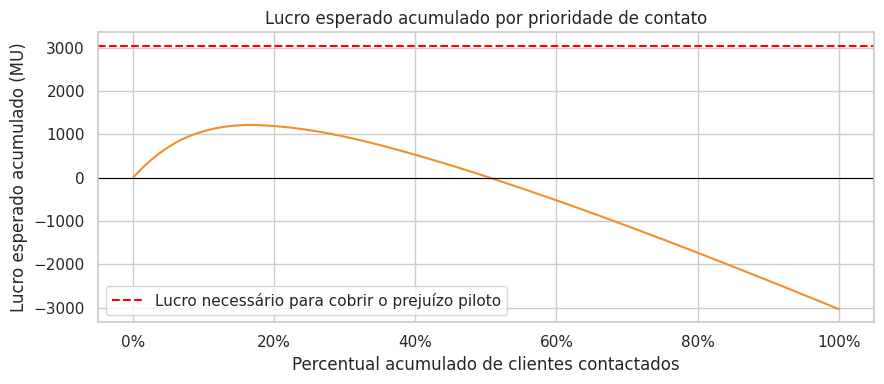

In [ ]:
ranked_score = score_df.sort_values('prioridade').reset_index(drop=True)
ranked_score['lucro_esperado_acumulado'] = ranked_score['lucro_esperado'].cumsum()
ranked_score['percentual_base'] = (np.arange(len(ranked_score)) + 1) / len(ranked_score)

plt.figure(figsize=(9, 4))
plt.plot(ranked_score['percentual_base'], ranked_score['lucro_esperado_acumulado'], color='#F28E2B')
plt.axhline(abs(pilot_result), color='red', linestyle='--', label='Lucro necessário para cobrir o prejuízo piloto')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Lucro esperado acumulado por prioridade de contato')
plt.xlabel('Percentual acumulado de clientes contactados')
plt.ylabel('Lucro esperado acumulado (MU)')
from matplotlib.ticker import PercentFormatter
plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))
plt.legend()
plt.tight_layout()

## 8. Bases recomendadas para contato

Geração da base com os clientes cujo lucro esperado é positivo. Também exporto uma alternativa limitada ao top 25% da base, caso exista uma restrição de capacidade de contato.

In [ ]:
contact_columns = [
    'ID', 'probabilidade_resposta', 'lucro_esperado', 'prioridade',
    'faixa_prioridade', 'PreviousAcceptedCampaigns', 'TotalSpend', 'Recency'
]

# Base principal: Apenas clientes com lucro esperado positivo.
contact_base = (
    score_df.loc[score_df['lucro_esperado'] > 0, contact_columns]
    .sort_values('prioridade')
)

contact_base.to_csv('clientes_priorizados_contato.csv', index=False, encoding='utf-8-sig')

# O arquivo fica disponível para visualização e download no notebook.
from IPython.display import FileLink, display as display_link
display_link(FileLink('clientes_priorizados_contato.csv'))

print(f'Base com lucro esperado positivo: {len(contact_base):,} clientes')
display(contact_base.head(15))

/content/clientes_priorizados_contato.csv

Base com lucro esperado positivo: 368 clientes


,ID,probabilidade_resposta,lucro_esperado,prioridade,faixa_prioridade,PreviousAcceptedCampaigns,TotalSpend,Recency
430,3725,0.992011,7.912120,1,Alta prioridade,4,1688,1
1961,3009,0.990350,7.893846,2,Alta prioridade,3,1766,8
252,10089,0.986270,7.848970,3,Alta prioridade,4,1112,5
1845,7872,0.979462,7.774082,4,Alta prioridade,3,557,7
586,9058,0.976559,7.742154,5,Alta prioridade,3,1867,65
336,7381,0.974931,7.724236,6,Alta prioridade,3,1442,10
1528,830,0.972163,7.693797,7,Alta prioridade,2,1658,5
1710,477,0.970801,7.678816,8,Alta prioridade,4,2157,31
1722,569,0.965098,7.616080,9,Alta prioridade,3,1991,32
987,4580,0.963399,7.597387,10,Alta prioridade,3,2486,46


## 9. Limitações e próximos passos

- O corte de 1936 é uma premissa de elegibilidade e deve ser validado com o negócio.
- A base original não é apagada: os registros sinalizados ficam disponíveis para auditoria e correção cadastral.
- A validação atual é aleatória; uma versão final deve preferir uma divisão temporal.
- Sem grupo de controle, não é possível medir compra incremental.
- O score depende da qualidade e da calibração das probabilidades.
- A próxima campanha deve reservar um grupo de controle aleatório e acompanhar conversão, receita, custo e lucro incremental.

**Conclusão:** o modelo ordena clientes por probabilidade e lucro esperado. A decisão final pode considerar o corte financeiro e a capacidade real de contato.